# 8. Assortativität

Kapitel 7 hat gezeigt, dass sich Athleten wiederholt treffen. Hier fragen wir, **wer** sich trifft: Verbinden sich Athleten bevorzugt mit ähnlichen Athleten? Grundlage ist das Arbeitsnetz (`weight >= 2`). Wir untersuchen Nation, Geschlecht, Jahrgang, Leistung (maximale FINA-Punkte) und Degree.

- Kategorische Attribute über die Mixing Matrix, numerische als Pearson-Korrelation über beide Kantenrichtungen, wie im Skript.
- Hypothesentest mit permutierten Attributen bei fester Netzwerkstruktur, wie in Kapitel 4. Der Degree stammt aus dem Netz selbst und wird deshalb mit dem bipartiten Configuration Model aus Kapitel 7 verglichen.
- Lokal getrennt nach internationalen Generationen und nationalen Communities, da ein globaler Wert lokale Muster verdecken kann.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import rankdata
from IPython.display import display

PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
NETWORK_DIR = PROJECT_ROOT / 'data/processed/networks'
RESULT_DIR = PROJECT_ROOT / 'data/processed/assortativitaet'
REPORT_DIR = PROJECT_ROOT / 'Report/graphics'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

WORK_THRESHOLD = 2
SEED = 42
N_PERMUTATIONS = 10_000
N_NULL = 100
ALPHA = 0.05
GENERATIONS = ['C4', 'C2', 'C3', 'C1']
COLOR, ORANGE, MUTED = '#367da2', '#eb6834', '#a3a29d'
REPORT_RC = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8,
             'xtick.labelsize': 7, 'ytick.labelsize': 7, 'pdf.fonttype': 42}
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

## 8.1 Arbeitsnetz und Attribute

Die Leistung ist der maximale FINA-Punktewert eines Athleten. Zusätzlich speichern wir das Jahr dieser besten Leistung, um später den Zeitraum herauszurechnen. Fehlende Werte werden nicht ersetzt. Kanten mit einem fehlenden Wert entfallen nur für das jeweilige Attribut.

In [2]:
G = nx.read_gexf(NETWORK_DIR / 'athletes.gexf')
nodes = sorted(G)
node_index = {node: i for i, node in enumerate(nodes)}
N = len(nodes)
W = nx.Graph()
W.add_nodes_from(range(N))
W.add_edges_from((node_index[u], node_index[v]) for u, v, w in G.edges(data='weight') if w >= WORK_THRESHOLD)
assert W.number_of_edges() == 357_219
edges = np.array(W.edges())
edge_u, edge_v = edges[:, 0], edges[:, 1]

records = pd.read_parquet(PROJECT_ROOT / 'data/processed/athlete_data_clean.parquet',
                          columns=['athlete_id', 'points', 'best_date']).dropna(subset=['points'])
best = records.loc[records.groupby('athlete_id')['points'].idxmax()]
best.index = 'athlete_' + best['athlete_id'].astype(str)

athletes = pd.DataFrame.from_dict(dict(G.nodes(data=True)), orient='index').loc[nodes]
attributes = pd.DataFrame({
    'nation': athletes['athlete_nation'].to_numpy(),
    'gender': athletes['gender'].to_numpy(),
    'birth_year': pd.to_numeric(athletes['birth_year'], errors='coerce').to_numpy(),
    'points': best['points'].reindex(nodes).to_numpy(dtype=float),
    'best_year': pd.to_datetime(best['best_date']).dt.year.reindex(nodes).to_numpy(dtype=float),
    'degree': np.array([W.degree(i) for i in range(N)], dtype=float),
}, index=nodes)
display(attributes.isna().sum().rename('Fehlende Werte').to_frame())

,Fehlende Werte
nation,0
gender,0
birth_year,69
points,3
best_year,3
degree,0


## 8.2 Assortativität

Kategorisch nach Skript: $r = (\sum_i e_{ii} - \sum_i a_i b_i) / (1 - \sum_i a_i b_i)$ aus der normierten Mixing Matrix, jede ungerichtete Kante zählt in beide Richtungen. Numerisch: Pearson-Korrelation der Attributwerte an beiden Kantenenden, ebenfalls in beide Richtungen. Als Robustheitsprüfung gegen Ausreisser berechnen wir die Rangvariante (Spearman). Beide Funktionen werden gegen NetworkX geprüft.

In [3]:
def categorical_assortativity(codes, u=edge_u, v=edge_v):
    """Assortativität aus der Mixing Matrix (beide Kantenrichtungen)."""
    a, b = codes[u], codes[v]
    keep = (a >= 0) & (b >= 0)
    a, b = a[keep], b[keep]
    k = max(a.max(), b.max()) + 1
    same = np.mean(a == b)
    ends = np.bincount(np.concatenate([a, b]), minlength=k) / (2 * len(a))
    expected = np.sum(ends ** 2)
    return (same - expected) / (1 - expected)


def numeric_assortativity(values, u=edge_u, v=edge_v, ranks=False):
    """Pearson- oder Rangkorrelation der Werte an beiden Kantenenden."""
    x, y = values[u], values[v]
    keep = ~(np.isnan(x) | np.isnan(y))
    x, y = np.concatenate([x[keep], y[keep]]), np.concatenate([y[keep], x[keep]])
    if ranks:
        x, y = rankdata(x), rankdata(y)
    return np.corrcoef(x, y)[0, 1]


codes = {name: pd.factorize(attributes[name])[0] for name in ['nation', 'gender']}
values = {name: attributes[name].to_numpy() for name in ['birth_year', 'points', 'degree']}

# Kontrolle gegen NetworkX
check = nx.Graph(); check.add_nodes_from((i, {'nation': attributes['nation'].iat[i]}) for i in range(N))
check.add_edges_from(edges)
assert np.isclose(categorical_assortativity(codes['nation']), nx.attribute_assortativity_coefficient(check, 'nation'))
assert np.isclose(numeric_assortativity(values['degree']), nx.degree_assortativity_coefficient(W))

observed = pd.DataFrame({
    'Assortativität r': [categorical_assortativity(codes['nation']), categorical_assortativity(codes['gender']),
                         numeric_assortativity(values['birth_year']), numeric_assortativity(values['points']),
                         numeric_assortativity(values['degree'])],
    'Rangvariante': [np.nan, np.nan, numeric_assortativity(values['birth_year'], ranks=True),
                     numeric_assortativity(values['points'], ranks=True),
                     numeric_assortativity(values['degree'], ranks=True)],
}, index=['Nation', 'Geschlecht', 'Jahrgang', 'Leistung', 'Degree'])
display(observed.round(3))

gender_mix = pd.crosstab(attributes['gender'].to_numpy()[np.r_[edge_u, edge_v]],
                         attributes['gender'].to_numpy()[np.r_[edge_v, edge_u]], normalize=True)
display(gender_mix.round(3).rename_axis(index='Kantenende', columns='anderes Ende'))

,Assortativität r,Rangvariante
Nation,0.423,NaN
Geschlecht,0.041,NaN
Jahrgang,0.851,0.839
Leistung,0.373,0.376
Degree,0.403,0.494


anderes Ende,female,male
Kantenende,,
female,0.200,0.236
male,0.236,0.328


## 8.3 Hypothesentests

Für Nation, Geschlecht, Jahrgang und Leistung gilt H0: Das Attribut hängt nicht mit den Kanten zusammen. Wir verteilen die Werte 10'000-mal zufällig auf die Athleten mit bekanntem Wert, die Netzwerkstruktur bleibt fest. Teststatistik ist die Assortativität r, einseitig, α = 0.05 mit Holm-Korrektur über die fünf Tests.

Der Degree entsteht aus dem Netz selbst, eine Permutation wäre deshalb nicht sinnvoll. Für ihn verwenden wir 100 Referenz-Netzwerke aus dem bipartiten Configuration Model von Kapitel 7 und vergleichen die Degree-Assortativität.

In [4]:
rng = np.random.default_rng(SEED)


def permutation_reference(statistic, data, missing):
    """Werte nur unter Athleten mit bekanntem Wert permutieren."""
    known = np.flatnonzero(~missing)
    out = np.empty(N_PERMUTATIONS)
    for k in range(N_PERMUTATIONS):
        shuffled = data.copy()
        shuffled[known] = data[known][rng.permutation(len(known))]
        out[k] = statistic(shuffled)
    return out


references = {
    'Nation': permutation_reference(categorical_assortativity, codes['nation'], codes['nation'] < 0),
    'Geschlecht': permutation_reference(categorical_assortativity, codes['gender'], codes['gender'] < 0),
    'Jahrgang': permutation_reference(numeric_assortativity, values['birth_year'], np.isnan(values['birth_year'])),
    'Leistung': permutation_reference(numeric_assortativity, values['points'], np.isnan(values['points'])),
}
print('Permutationen abgeschlossen.')

Permutationen abgeschlossen.


In [5]:
participations = pd.read_parquet(NETWORK_DIR / 'athlete_events.parquet', columns=['athlete_node', 'event_id'])
participations['a'] = participations['athlete_node'].map(node_index)


def project(rows, threshold=WORK_THRESHOLD):
    """Athletenprojektion mit Mindestgewicht (wie in Kapitel 7)."""
    rows = rows.sort_values(['event_id', 'a'])
    member_codes = rows['a'].to_numpy()
    bounds = np.flatnonzero(np.diff(pd.factorize(rows['event_id'])[0])) + 1
    left, right = [], []
    for members in np.split(member_codes, bounds):
        if len(members) > 1:
            i, j = np.triu_indices(len(members), 1)
            left.append(members[i])
            right.append(members[j])
    keys = np.concatenate(left).astype(np.int64) * N + np.concatenate(right)
    pairs, counts = np.unique(keys, return_counts=True)
    pairs = pairs[counts >= threshold]
    graph = nx.Graph()
    graph.add_nodes_from(range(N))
    graph.add_edges_from(zip((pairs // N).tolist(), (pairs % N).tolist()))
    return graph


null_degree = []
for _ in range(N_NULL):
    shuffled = participations[['a', 'event_id']].assign(a=rng.permutation(participations['a'].to_numpy()))
    null_degree.append(nx.degree_assortativity_coefficient(project(shuffled.drop_duplicates())))
references['Degree'] = np.array(null_degree)

tests = pd.DataFrame({
    'r': observed['Assortativität r'],
    'Referenz Mittel': {k: v.mean() for k, v in references.items()},
    'Referenz Maximum': {k: v.max() for k, v in references.items()},
    'Referenz': {k: ('bipartites Configuration Model' if k == 'Degree' else 'Permutation') for k in references},
    'n Referenz': {k: len(v) for k, v in references.items()},
    'p': {k: (v >= observed.loc[k, 'Assortativität r']).mean() for k, v in references.items()},
})
order = tests['p'].sort_values().index
holm = np.maximum.accumulate([min(1, p * (len(order) - i)) for i, p in enumerate(tests.loc[order, 'p'])])
tests.loc[order, 'p Holm'] = holm
tests['H0 verwerfen'] = tests['p Holm'] < ALPHA
display(tests.round(4))

,r,Referenz Mittel,Referenz Maximum,Referenz,n Referenz,p,p Holm,H0 verwerfen
Nation,0.4234,-0.0002,0.0006,Permutation,10000,0.0,0.0,True
Geschlecht,0.0406,-0.0002,0.0075,Permutation,10000,0.0,0.0,True
Jahrgang,0.8506,-0.0002,0.0058,Permutation,10000,0.0,0.0,True
Leistung,0.3729,-0.0001,0.0069,Permutation,10000,0.0,0.0,True
Degree,0.4028,0.1215,0.1590,bipartites Configuration Model,100,0.0,0.0,True


Alle Attribute sind assortativ. Am stärksten verbinden sich Athleten gleichen Jahrgangs (r = 0.85), danach folgen Nation (0.42), Degree (0.40) und Leistung (0.37). Das Geschlecht ist mit 0.04 vernachlässigbar, wie schon in Kapitel 4. Keine Permutation erreicht einen der beobachteten Werte (p < 0.0001). Auch die Degree-Assortativität liegt klar über dem bipartiten Configuration Model (Mittel 0.12, Maximum 0.16, p < 0.01). Athleten mit vielen Kontakten treffen sich also häufiger untereinander, als die Projektion allein erklärt. Die Rangvarianten bestätigen die Werte, Ausreisser treiben sie nicht.

Zur Abgrenzung von Kapitel 4: Dort war r die Korrelation über alle Athletenpaare (Nation 0.25), hier über die Kanten (0.42). Beide messen dieselbe Tendenz, aber anders normiert.

## 8.4 Jahrgang: wer trifft wen?

Die Jahrgangsdifferenz verbundener Athleten im Vergleich zu zufälligen Athletenpaaren mit bekanntem Jahrgang. Die zufälligen Paare werden gleich oft gezogen wie Kanten mit bekannten Jahrgängen vorhanden sind.

Median Jahrgangsdifferenz: Kanten 3, zufällige Paare 9
Höchstens 2 Jahre Differenz: Kanten 46.9%, zufällige Paare 16.2%


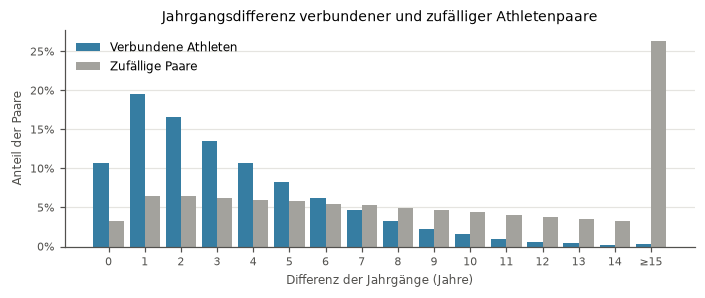

In [6]:
years = values['birth_year']
known_edges = ~(np.isnan(years[edge_u]) | np.isnan(years[edge_v]))
edge_diff = np.abs(years[edge_u] - years[edge_v])[known_edges]
known_nodes = np.flatnonzero(~np.isnan(years))
pick = rng.choice(known_nodes, size=(len(edge_diff), 2))
pick = pick[pick[:, 0] != pick[:, 1]]
random_diff = np.abs(years[pick[:, 0]] - years[pick[:, 1]])

MAX_DIFF = 15
bins = np.arange(MAX_DIFF + 2)
diff_table = pd.DataFrame({
    'Kanten': np.histogram(np.minimum(edge_diff, MAX_DIFF), bins=bins)[0] / len(edge_diff),
    'Zufällige Paare': np.histogram(np.minimum(random_diff, MAX_DIFF), bins=bins)[0] / len(random_diff),
}, index=bins[:-1])
print(f'Median Jahrgangsdifferenz: Kanten {np.median(edge_diff):.0f}, zufällige Paare {np.median(random_diff):.0f}')
print(f'Höchstens 2 Jahre Differenz: Kanten {np.mean(edge_diff <= 2):.1%}, zufällige Paare {np.mean(random_diff <= 2):.1%}')

with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 2.6), layout='constrained')
    width = 0.42
    ax.bar(diff_table.index - width / 2, diff_table['Kanten'], width=width, color=COLOR, label='Verbundene Athleten')
    ax.bar(diff_table.index + width / 2, diff_table['Zufällige Paare'], width=width, color=MUTED,
           label='Zufällige Paare')
    ax.set_xticks(diff_table.index, [str(i) for i in diff_table.index[:-1]] + [f'≥{MAX_DIFF}'])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set(xlabel='Differenz der Jahrgänge (Jahre)', ylabel='Anteil der Paare',
           title='Jahrgangsdifferenz verbundener und zufälliger Athletenpaare')
    ax.grid(axis='x', visible=False)
    ax.legend(frameon=False)
    fig.savefig(REPORT_DIR / '08_jahrgang.pdf', bbox_inches='tight')
    plt.show()

Verbundene Athleten unterscheiden sich im Median um 3 Jahrgänge, zufällige Paare um 9. Fast die Hälfte der verbundenen Paare (46.9 %) liegt höchstens zwei Jahre auseinander, bei zufälligen Paaren sind es 16.2 %. Das erklärt auch die Generationen-Communities aus Kapitel 5.

## 8.5 Lokal: Generationen und nationale Communities

Ein globaler Wert kann lokale Muster verdecken. Wir berechnen die Assortativität von Leistung und Jahrgang deshalb getrennt für Kanten innerhalb jeder Generation C1 bis C4 und für Kanten innerhalb der nationalen Communities aus Kapitel 5 (mindestens 150 Athleten, mindestens 90 % aus einer Nation), die wir als eine Gruppe zusammenfassen.

Vor dem Zusammenfassen der nationalen Communities werden die Werte je Community zentriert (Mittelwert der Community abgezogen). Sonst würden die unterschiedlichen Leistungsniveaus der Nationen eine Assortativität vortäuschen, obwohl innerhalb jeder Nation Starke und Schwächere gemischt sind. Für eine einzelne Community ändert die Zentrierung den Wert nicht.

11 nationale Communities: C10 (Serbia), C12 (Poland), C15 (Slovakia), C17 (Norway), C18 (Latvia), C20 (Austria), C21 (New Zealand), C22 (Ireland), C23 (Finland), C8 (Spain), C9 (Türkiye)


,Kanten,Leistung,Jahrgang
C4,16375.0,0.124,0.605
C2,63652.0,0.200,0.231
C3,34501.0,0.154,0.260
C1,51669.0,0.427,0.401
National,47328.0,0.024,0.650


,Nation,Leistung,Jahrgang
C10,Serbia,0.015045,0.652729
C12,Poland,0.03518,0.694895
C15,Slovakia,0.037474,0.774035
C17,Norway,0.009628,0.618289
C18,Latvia,0.010986,0.685886
C20,Austria,0.044884,0.701268
C21,New Zealand,-0.008907,0.691817
C22,Ireland,0.032867,0.648372
C23,Finland,0.000829,0.568085
C8,Spain,0.0337,0.563755


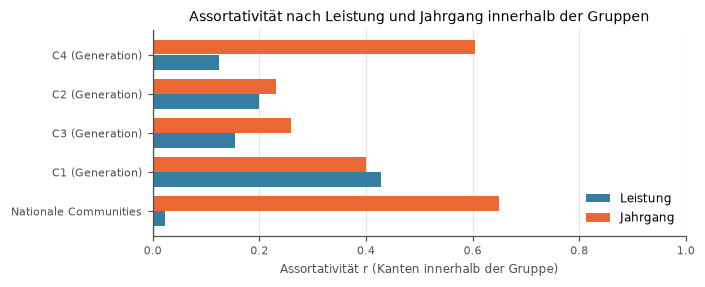

In [7]:
communities = pd.read_parquet(NETWORK_DIR / 'athlete_communities.parquet').set_index('node')['louvain'].reindex(nodes)
community_size = communities.value_counts()
dominant_share = attributes['nation'].groupby(communities).agg(lambda s: s.value_counts(normalize=True).iloc[0])
national = dominant_share.index[(dominant_share >= 0.9) & (community_size.reindex(dominant_share.index) >= 150)]
print(f'{len(national)} nationale Communities:', ', '.join(
    f"{c} ({attributes['nation'][communities.eq(c)].value_counts().index[0]})" for c in national))

label = communities.to_numpy()
same_community = label[edge_u] == label[edge_v]
groups = {g: same_community & (label[edge_u] == g) for g in GENERATIONS}
groups['National'] = same_community & np.isin(label[edge_u], national)

# Werte je Community zentrieren, damit Niveauunterschiede zwischen Communities nichts vortäuschen.
centered = {name: values[name] - pd.Series(values[name]).groupby(label).transform('mean').to_numpy()
            for name in ['points', 'birth_year']}
local = pd.DataFrame({
    name: {'Kanten': int(mask.sum()),
           'Leistung': numeric_assortativity(centered['points'], edge_u[mask], edge_v[mask]),
           'Jahrgang': numeric_assortativity(centered['birth_year'], edge_u[mask], edge_v[mask])}
    for name, mask in groups.items()
}).T
display(local.round(3))

per_national = pd.DataFrame({
    c: {'Nation': attributes['nation'][communities.eq(c)].value_counts().index[0],
        'Leistung': numeric_assortativity(values['points'], edge_u[same_community & (label[edge_u] == c)],
                                          edge_v[same_community & (label[edge_u] == c)]),
        'Jahrgang': numeric_assortativity(values['birth_year'], edge_u[same_community & (label[edge_u] == c)],
                                          edge_v[same_community & (label[edge_u] == c)])}
    for c in national
}).T
display(per_national.round(3))

with plt.rc_context(REPORT_RC):
    fig, ax = plt.subplots(figsize=(6.3, 2.5), layout='constrained')
    positions = np.arange(len(local))
    ax.barh(positions + 0.2, local['Leistung'], height=0.38, color=COLOR, label='Leistung')
    ax.barh(positions - 0.2, local['Jahrgang'], height=0.38, color=ORANGE, label='Jahrgang')
    ax.set_yticks(positions, [f'{g} (Generation)' if g != 'National' else 'Nationale Communities'
                              for g in local.index])
    ax.invert_yaxis()
    ax.axvline(0, color='#52514e', linewidth=0.8)
    ax.set(xlabel='Assortativität r (Kanten innerhalb der Gruppe)', xlim=(0, 1),
           title='Assortativität nach Leistung und Jahrgang innerhalb der Gruppen')
    ax.grid(axis='y', visible=False)
    ax.legend(frameon=False, loc='lower right')
    fig.savefig(REPORT_DIR / '08_lokal.pdf', bbox_inches='tight')
    plt.show()

Die Muster unterscheiden sich deutlich. In der jüngsten Generation C1 treffen sich starke Schwimmer bevorzugt mit starken (Leistung 0.43). In den älteren Generationen ist dieser Effekt schwächer (0.12 bis 0.20). Innerhalb der nationalen Communities fehlt er fast ganz (0.02, jede einzelne zwischen -0.01 und 0.05), dafür prägt dort der Jahrgang besonders stark (0.65). National treffen sich also Gleichaltrige unabhängig von ihrem Niveau, etwa an Meisterschaften mit Altersklassen. Ein Elite-Club, in dem sich Starke mit Starken treffen, entsteht erst international und vor allem in der aktuellen Generation.

## 8.6 Leistung: Kontrolle für Jahrgang und Zeitraum

Athleten mit gemeinsamen Tagen sind oft gleich alt und haben ihre beste Leistung oft im selben Jahr erzielt. FINA-Punktetabellen und Hightech-Anzüge (2008/09) verändern die Punkte je nach Jahr. Wir ziehen deshalb vom Punktewert den Mittelwert aller Athleten desselben Jahrgangs bzw. desselben Jahrs der besten Leistung ab und berechnen die Assortativität erneut.

In [8]:
def residual(points, group):
    frame = pd.DataFrame({'points': points, 'group': group})
    return (frame['points'] - frame.groupby('group')['points'].transform('mean')).to_numpy()


controls = pd.Series({
    'Ohne Kontrolle': numeric_assortativity(values['points']),
    'Ohne Jahrgangseffekt': numeric_assortativity(residual(values['points'], attributes['birth_year'].to_numpy())),
    'Ohne Effekt des Leistungsjahrs': numeric_assortativity(residual(values['points'], attributes['best_year'].to_numpy())),
}, name='Leistungsassortativität')
display(controls.round(3).to_frame())

,Leistungsassortativität
Ohne Kontrolle,0.373
Ohne Jahrgangseffekt,0.359
Ohne Effekt des Leistungsjahrs,0.349


Die Leistungsassortativität bleibt fast unverändert, wenn wir den Jahrgang (0.36) oder das Jahr der besten Leistung (0.35) herausrechnen. Sie entsteht also nicht nur dadurch, dass Gleichaltrige oder Athleten derselben Saison verbunden sind, deren Punkte durch Punktetabellen oder Anzüge ähnlich verschoben sind.

## 8.7 Export

Die Attribute pro Athlet und die Ergebnisse werden für die Link Prediction gespeichert. Dort dienen gleiche Nation, kleine Jahrgangsdifferenz und ähnliche Leistung als einfache Faustregeln zum Vergleich mit den Netzwerkverfahren.

In [9]:
attributes.drop(columns='degree').to_parquet(RESULT_DIR / 'athlete_attributes.parquet')
tests.to_parquet(RESULT_DIR / 'tests.parquet')
local.to_parquet(RESULT_DIR / 'lokal.parquet')
controls.to_frame().to_parquet(RESULT_DIR / 'leistung_kontrollen.parquet')
diff_table.to_parquet(RESULT_DIR / 'jahrgangsdifferenz.parquet')
print('Gespeichert in', RESULT_DIR.relative_to(PROJECT_ROOT))

Gespeichert in data/processed/assortativitaet
